<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/5_gravity_cosmo_strings/cosmology/cosmo_colab_visualizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Cosmology* — `cosmo_colab_visualizations.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Cosmology — Interactive Visualizations
### David Tong's Cosmology Notes · Chapters 1, 2 & 3

Seven interactive plots covering the key results from all three chapters.

| Plot | Chapter | Topic |
|------|---------|-------|
| 1 | Ch 1 | Scale factor $a(t)$: expanding universe models |
| 2 | Ch 1 | Energy density evolution $\rho(a)$ and cosmic epochs |
| 3 | Ch 1 | Inflation: co-moving horizon and mode exit/re-entry |
| 4 | Ch 2 | Thermal history: $T(t)$ from BBN to today |
| 5 | Ch 2 | Saha equation: ionisation fraction $X_e(T)$ |
| 6 | Ch 3 | Matter power spectrum $P(k)$ with transfer function |
| 7 | Ch 3 | Spherical collapse: true $\delta$ vs linear theory |

**Run all cells** (Runtime → Run all) to generate the figures.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
import warnings
warnings.filterwarnings('ignore')

# ── Dark theme ────────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.facecolor':  '#080c14',
    'axes.facecolor':    '#0f1825',
    'axes.edgecolor':    '#1e2d42',
    'axes.labelcolor':   '#e2eaf4',
    'axes.titlecolor':   '#e8b84b',
    'xtick.color':       '#7a9ab8',
    'ytick.color':       '#7a9ab8',
    'text.color':        '#e2eaf4',
    'grid.color':        '#1e2d42',
    'grid.linewidth':    0.6,
    'legend.facecolor':  '#0f1825',
    'legend.edgecolor':  '#1e2d42',
    'legend.labelcolor': '#e2eaf4',
    'font.family':       'DejaVu Sans',
    'font.size':         11,
    'axes.titlesize':    13,
    'axes.labelsize':    11,
})

# Colour palette
GOLD   = '#e8b84b'
BLUE   = '#4ca8f0'
GREEN  = '#3ecf8e'
RED    = '#f06060'
PURPLE = '#c084fc'
ORANGE = '#f59e42'
MUTED  = '#7a9ab8'

print('Setup complete — ready to plot.')

Setup complete — ready to plot.


---
## Plot 1 · Scale Factor $a(t)$ — Expanding Universe Models (Ch 1)

The Friedmann equation for a flat universe:
$$H^2 = \left(\frac{\dot a}{a}\right)^2 = H_0^2\left(\frac{\Omega_r}{a^4} + \frac{\Omega_m}{a^3} + \Omega_\Lambda\right)$$

Analytic solutions for single-component flat universes:
- **Radiation** ($w=1/3$): $a\propto t^{1/2}$
- **Matter** ($w=0$): $a\propto t^{2/3}$ (Einstein–de Sitter)
- **$\Lambda$** ($w=-1$): $a\propto e^{Ht}$ (de Sitter)
- **Our universe**: numerical solution with $\Omega_m=0.31$, $\Omega_\Lambda=0.69$

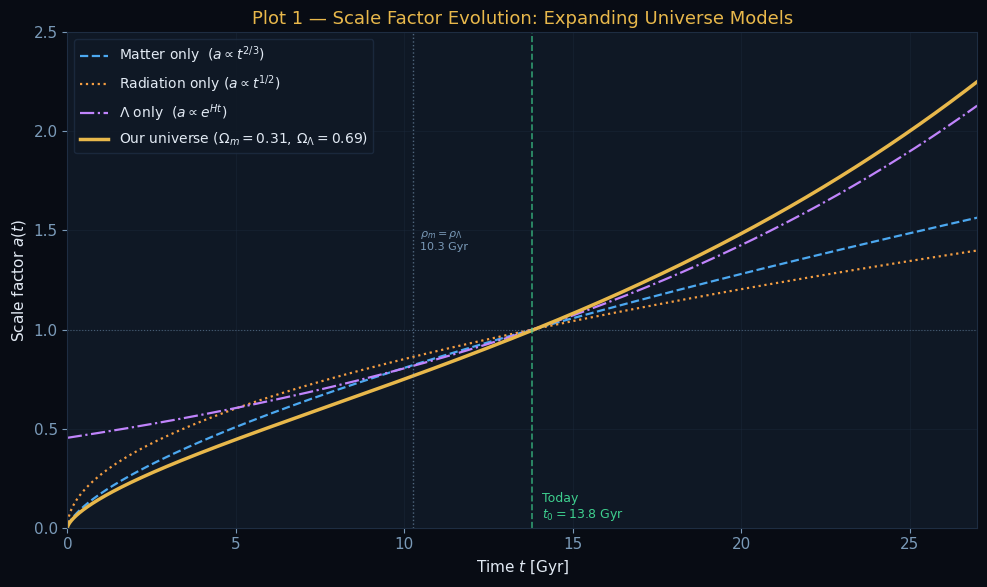

Plot 1 saved.


In [2]:
# ── Physical parameters ───────────────────────────────────────────────────────
H0      = 67.4          # km/s/Mpc
H0_si   = H0 * 1e3 / 3.086e22  # s^-1
t_H     = 1.0 / H0_si / (3.156e7 * 1e9)  # Hubble time in Gyr
Om_m    = 0.31
Om_r    = 9.0e-5
Om_L    = 0.69
t0_Gyr  = 13.8          # age of universe in Gyr

# ── Numerical solution of Friedmann for real universe ────────────────────────
def friedmann_rhs(t, a):
    """da/dt = a * H  with H(a) from Friedmann."""
    H2 = H0_si**2 * (Om_r / a**4 + Om_m / a**3 + Om_L)
    H2 = max(H2, 0.0)
    return [np.sqrt(H2) * a[0]]

# Integrate from a_i to a_f
a_i = 1e-4
t_i = 0.0
# Find t at a=a_i numerically: t = integral of da/(a*H)
def integrand_t(a_val):
    H = H0_si * np.sqrt(Om_r/a_val**4 + Om_m/a_val**3 + Om_L)
    return 1.0 / (a_val * H)
t_start, _ = quad(integrand_t, 1e-6, a_i)
t_end = 2.0 * t0_Gyr * 3.156e16  # 2×t0 in seconds

sol = solve_ivp(friedmann_rhs, [t_start, t_end], [a_i],
                dense_output=True, max_step=t_end/5000, rtol=1e-8)

t_gyr = sol.t / 3.156e16  # convert to Gyr
a_num = sol.y[0]

# ── Analytic single-component solutions (normalised to a=1 at t=t0) ──────────
t_arr = np.linspace(0.01, 28, 2000)
# Matter: a ∝ t^{2/3}
a_mat = (t_arr / t0_Gyr) ** (2/3)
# Radiation: a ∝ t^{1/2}
a_rad = (t_arr / t0_Gyr) ** (1/2)
# Lambda (de Sitter): a ∝ e^{H0*sqrt(OmL)*t}
H_dS  = H0_si * np.sqrt(Om_L)
t_dS  = t0_Gyr * 3.156e16
a_dS  = np.exp(H_dS * (t_arr - t0_Gyr) * 3.156e16)  # normalised at t0

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(t_arr, a_mat, color=BLUE,   lw=1.6, ls='--', label=r'Matter only  ($a\propto t^{2/3}$)')
ax.plot(t_arr, a_rad, color=ORANGE, lw=1.6, ls=':',  label=r'Radiation only ($a\propto t^{1/2}$)')
ax.plot(t_arr, a_dS,  color=PURPLE, lw=1.6, ls='-.', label=r'$\Lambda$ only  ($a\propto e^{Ht}$)')
ax.plot(t_gyr, a_num, color=GOLD,   lw=2.5,           label=r'Our universe ($\Omega_m=0.31,\,\Omega_\Lambda=0.69$)')

# Milestones
ax.axvline(t0_Gyr, color=GREEN, lw=1.2, ls='--', alpha=0.7)
ax.text(t0_Gyr + 0.3, 0.05, 'Today\n$t_0=13.8$ Gyr', color=GREEN, fontsize=9)
ax.axhline(1.0, color=MUTED, lw=0.8, ls=':', alpha=0.5)

# Matter-Λ equality
a_eq_L = (Om_m / Om_L) ** (1/3)
t_eq_L_s, _ = quad(integrand_t, 1e-6, a_eq_L)
t_eq_L_gyr  = t_eq_L_s / 3.156e16
ax.axvline(t_eq_L_gyr, color=MUTED, lw=1.0, ls=':', alpha=0.6)
ax.text(t_eq_L_gyr + 0.2, 1.4, r'$\rho_m=\rho_\Lambda$'+f'\n{t_eq_L_gyr:.1f} Gyr', color=MUTED, fontsize=8)

ax.set_xlabel('Time $t$ [Gyr]')
ax.set_ylabel('Scale factor $a(t)$')
ax.set_title('Plot 1 — Scale Factor Evolution: Expanding Universe Models')
ax.set_xlim(0, 27); ax.set_ylim(0, 2.5)
ax.grid(True, alpha=0.4)
ax.legend(loc='upper left', fontsize=10)
plt.tight_layout()
plt.savefig('cosmo_plot1_scale_factor.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Plot 1 saved.')

---
## Plot 2 · Energy Density Evolution $\rho(a)$ — Cosmic Epochs (Ch 1)

Each component scales differently:
$$\rho_r \propto a^{-4}, \quad \rho_m \propto a^{-3}, \quad \rho_\Lambda = \text{const}$$

Equality redshifts: $z_\text{eq}^{rm}\approx3400$ (radiation–matter), $z_\text{eq}^{m\Lambda}\approx0.3$ (matter–$\Lambda$).

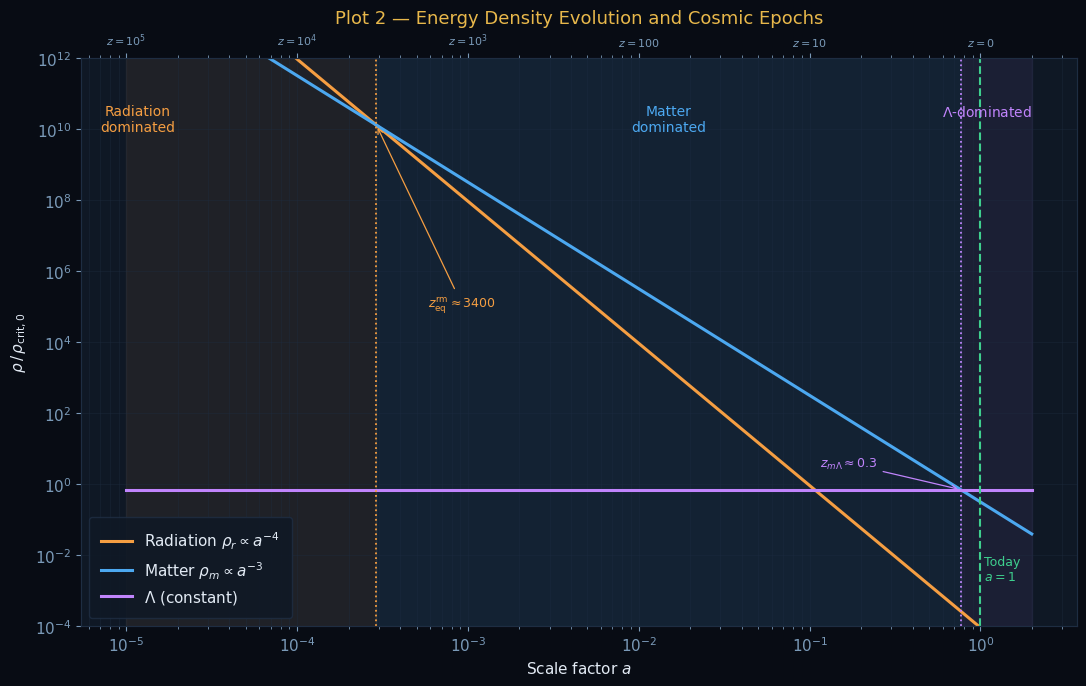

Plot 2 saved.


In [3]:
H0_si = 67.4e3 / 3.086e22
Om_m, Om_r, Om_L = 0.31, 9.0e-5, 0.69

a_vals = np.logspace(-5, 0.3, 1000)
rho_r  = Om_r / a_vals**4
rho_m  = Om_m / a_vals**3
rho_L  = Om_L * np.ones_like(a_vals)

a_eq_rm = Om_r / Om_m
a_eq_mL = (Om_m / Om_L)**(1/3)

fig, ax = plt.subplots(figsize=(11, 7))

ax.loglog(a_vals, rho_r, color=ORANGE, lw=2.2, label=r'Radiation $\rho_r \propto a^{-4}$')
ax.loglog(a_vals, rho_m, color=BLUE,   lw=2.2, label=r'Matter $\rho_m \propto a^{-3}$')
ax.loglog(a_vals, rho_L, color=PURPLE, lw=2.2, label=r'$\Lambda$ (constant)')

ax.axvspan(a_vals[0], a_eq_rm, color=ORANGE, alpha=0.07)
ax.axvspan(a_eq_rm,  a_eq_mL,  color=BLUE,   alpha=0.07)
ax.axvspan(a_eq_mL,  a_vals[-1], color=PURPLE, alpha=0.07)

ax.axvline(a_eq_rm, color=ORANGE, lw=1.3, ls=':')
ax.axvline(a_eq_mL, color=PURPLE, lw=1.3, ls=':')
ax.axvline(1.0,     color=GREEN,  lw=1.5, ls='--')

# Epoch labels at top of bands
ax.text(a_eq_rm * 0.04, 5e10, 'Radiation\ndominated',
        color=ORANGE, fontsize=10, ha='center', va='top')
ax.text(np.sqrt(a_eq_rm * a_eq_mL), 5e10, 'Matter\ndominated',
        color=BLUE,   fontsize=10, ha='center', va='top')
ax.text(a_vals[-1] * 0.55, 5e10, r'$\Lambda$-dominated',
        color=PURPLE, fontsize=10, ha='center', va='top')

# Equality annotations with arrows
ax.annotate(r'$z_\mathrm{eq}^\mathrm{rm}\approx3400$',
            xy=(a_eq_rm, Om_r / a_eq_rm**4),
            xytext=(a_eq_rm * 2, 1e5),
            color=ORANGE, fontsize=9,
            arrowprops=dict(arrowstyle='->', color=ORANGE, lw=0.9))
ax.annotate(r'$z_{m\Lambda}\approx0.3$',
            xy=(a_eq_mL, Om_L),
            xytext=(a_eq_mL * 0.15, 3),
            color=PURPLE, fontsize=9,
            arrowprops=dict(arrowstyle='->', color=PURPLE, lw=0.9))
ax.text(1.05, 2e-3, 'Today\n$a=1$', color=GREEN, fontsize=9)

# Redshift secondary x-axis
ax2 = ax.twiny()
ax2.set_xscale('log')
ax2.set_xlim(ax.get_xlim())
a_ticks  = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]
z_labels = ['$z=10^5$','$z=10^4$','$z=10^3$','$z=100$','$z=10$','$z=0$']
ax2.set_xticks(a_ticks)
ax2.set_xticklabels(z_labels, color=MUTED, fontsize=8)
ax2.tick_params(colors=MUTED)

ax.set_xlabel('Scale factor $a$')
ax.set_ylabel(r'$\rho\,/\,\rho_{\mathrm{crit},0}$')
ax.set_title('Plot 2 — Energy Density Evolution and Cosmic Epochs')
ax.set_ylim(1e-4, 1e12)
ax.grid(True, alpha=0.4, which='both')
ax.legend(loc='lower left', fontsize=11, framealpha=0.85,
          borderpad=0.8, labelspacing=0.5)

plt.tight_layout()
plt.savefig('cosmo_plot2_energy_density.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Plot 2 saved.')


---
## Plot 3 · Inflation: Co-moving Horizon and Mode Exit/Re-entry (Ch 1)

The co-moving Hubble radius $(aH)^{-1}$:
- **Shrinks** during inflation → modes exit the horizon, freeze
- **Grows** during radiation/matter era → modes re-enter

This resolves the **horizon problem**: all observed modes were once causally connected inside the horizon.

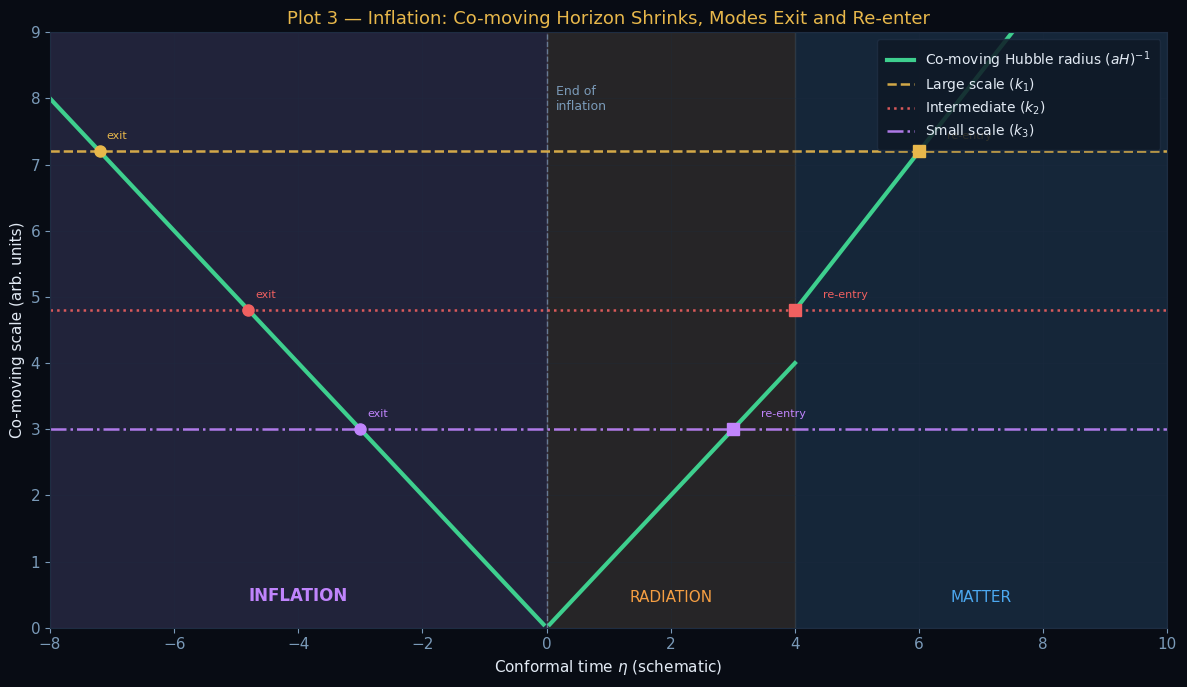

Plot 3 saved.


In [4]:
eta_inf = np.linspace(-8, -0.05, 300)
eta_rad = np.linspace(0.05, 4.0,  300)
eta_mat = np.linspace(4.0,  10.0, 300)
cH_inf  = np.abs(eta_inf)
cH_rad  = eta_rad
cH_mat  = eta_mat * 1.2

fig, ax = plt.subplots(figsize=(12, 7))

ax.axvspan(-8, 0,  color=PURPLE, alpha=0.10)
ax.axvspan( 0, 4,  color=ORANGE, alpha=0.10)
ax.axvspan( 4, 10, color=BLUE,   alpha=0.10)

ax.plot(eta_inf, cH_inf, color=GREEN, lw=3.0,
        label=r'Co-moving Hubble radius $(aH)^{-1}$')
ax.plot(eta_rad, cH_rad, color=GREEN, lw=3.0)
ax.plot(eta_mat, cH_mat, color=GREEN, lw=3.0)

ax.axvline(0, color=MUTED, lw=1.0, ls='--', alpha=0.7)

modes = [
    (7.2, GOLD,   r'Large scale ($k_1$)',  '--'),
    (4.8, RED,    r'Intermediate ($k_2$)', ':'),
    (3.0, PURPLE, r'Small scale ($k_3$)',  '-.'),
]
eta_post = np.concatenate([eta_rad, eta_mat])
cH_post  = np.concatenate([cH_rad,  cH_mat])

for k_val, col, label, ls in modes:
    ax.axhline(k_val, color=col, lw=1.8, ls=ls, alpha=0.9, label=label)
    idx = np.argmin(np.abs(cH_inf - k_val))
    eta_exit = eta_inf[idx]
    ax.plot(eta_exit, k_val, 'o', color=col, ms=8, zorder=6)
    ax.text(eta_exit +0.45, k_val + 0.15, 'exit',
            color=col, fontsize=8, ha='right', va='bottom')
    diff = np.abs(cH_post - k_val)
    if diff.min() < k_val * 0.25:
        idx2   = diff.argmin()
        eta_re = eta_post[idx2]
        ax.plot(eta_re, k_val, 's', color=col, ms=8, zorder=6)
        ax.text(eta_re + 0.45, k_val + 0.15, 're-entry',
                color=col, fontsize=8, ha='left', va='bottom')

# Epoch labels at bottom of bands
ax.text(-4.0, 0.35, 'INFLATION', color=PURPLE, fontsize=12,
        fontweight='bold', ha='center', va='bottom')
ax.text( 2.0, 0.35, 'RADIATION', color=ORANGE, fontsize=11, ha='center', va='bottom')
ax.text( 7.0, 0.35, 'MATTER',    color=BLUE,   fontsize=11, ha='center', va='bottom')
ax.text( 0.15, 8.2, 'End of\ninflation', color=MUTED, fontsize=9, va='top')

ax.legend(loc='upper right', fontsize=10, framealpha=0.85,
          borderpad=0.7, labelspacing=0.4)
ax.set_xlabel(r'Conformal time $\eta$ (schematic)', fontsize=11)
ax.set_ylabel(r'Co-moving scale (arb. units)', fontsize=11)
ax.set_title('Plot 3 — Inflation: Co-moving Horizon Shrinks, Modes Exit and Re-enter')
ax.set_xlim(-8, 10); ax.set_ylim(0, 9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('cosmo_plot3_inflation_horizon.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Plot 3 saved.')


---
## Plot 4 · Thermal History: $T(t)$ from BBN to Today (Ch 2)

In radiation domination:
$$\frac{t}{1\,\text{s}} \approx \frac{2.4}{\sqrt{g_\star}} \left(\frac{1\,\text{MeV}}{k_BT}\right)^2$$

Key milestones: neutrino decoupling, BBN, recombination, reionisation.

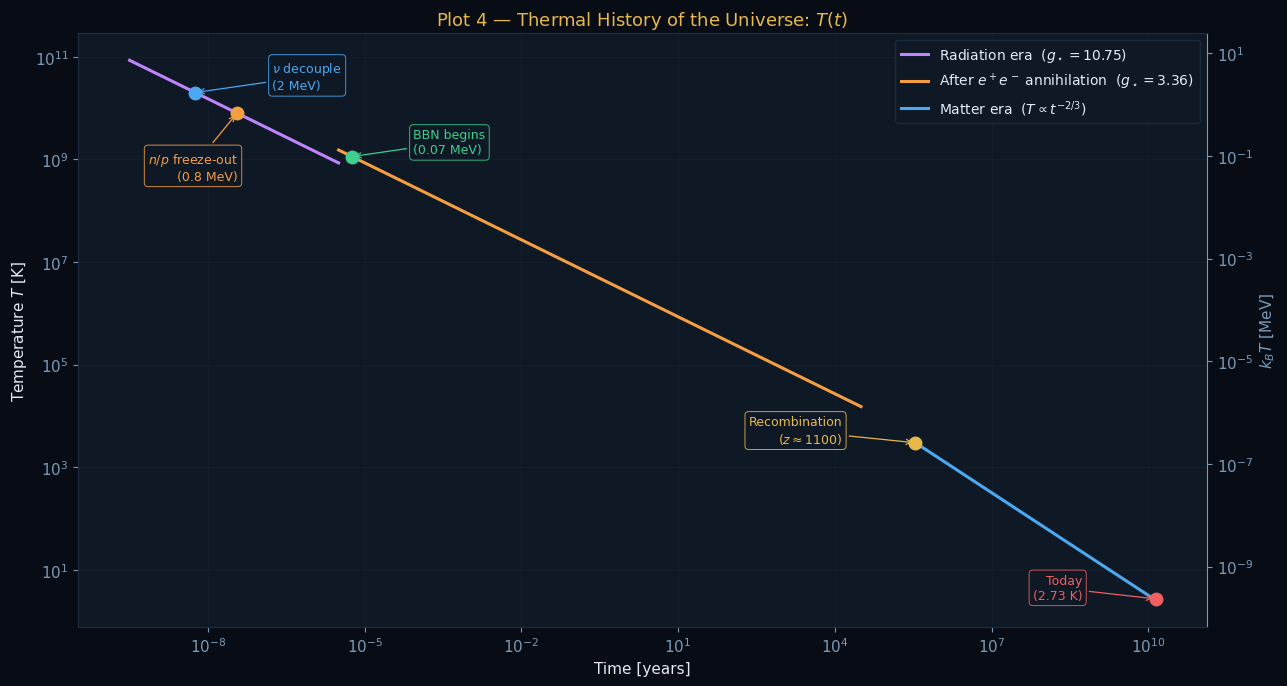

Plot 4 saved.


In [5]:
kB_eV  = 8.617e-5
kB_MeV = kB_eV * 1e-6
yr     = 3.156e7

def T_rad(t_s, gstar=10.75):
    kT_MeV = (2.4 / np.sqrt(gstar)) / np.sqrt(t_s)
    return kT_MeV / kB_MeV

t_early  = np.logspace(-2, 2,  300)
t_mid    = np.logspace( 2, 12, 300)
T_early  = T_rad(t_early, gstar=10.75)
T_mid    = T_rad(t_mid,   gstar=3.36)

T_rec_K   = 3000.0
t_rec_s   = 1.1e13
t_today_s = 4.35e17
t_matter  = np.logspace(13, np.log10(t_today_s), 200)
T_matter  = T_rec_K * (t_rec_s / t_matter)**(2/3)

fig, ax = plt.subplots(figsize=(13, 7))

ax.loglog(t_early/yr,  T_early,  color=PURPLE, lw=2.2,
          label=r'Radiation era  ($g_\star = 10.75$)')
ax.loglog(t_mid/yr,    T_mid,    color=ORANGE, lw=2.2,
          label=r'After $e^+e^-$ annihilation  ($g_\star = 3.36$)')
ax.loglog(t_matter/yr, T_matter, color=BLUE,   lw=2.2,
          label=r'Matter era  ($T \propto t^{-2/3}$)')

# Milestones: (t_s, T_K, label, color, dx_factor, dy_factor, ha)
milestones = [
    (0.18,    T_rad(0.18),        r'$\nu$ decouple' +'\n'+ r'(2 MeV)',
     BLUE,   30,   1.15, 'left'),
    (1.14,    T_rad(1.14),        r'$n/p$ freeze-out'+'\n'+ r'(0.8 MeV)',
     ORANGE,  1.04, 0.05,   'right'),
    (180,     T_rad(180, 3.36),   r'BBN begins'+'\n'+ r'(0.07 MeV)',
     GREEN,   15,  1.15, 'left'),
    (t_rec_s, T_rec_K,            r'Recombination'+'\n'+ r'($z\approx1100$)',
     GOLD,    0.04, 1,   'right'),
    (t_today_s, 2.726,            r'Today'+'\n'+ r'(2.73 K)',
     RED,     0.04, 1,   'right'),
]

for t_s, T_K, label, col, dx, dy, ha in milestones:
    t_yr = t_s / yr
    ax.plot(t_yr, T_K, 'o', color=col, ms=9, zorder=5)
    ax.annotate(label,
                xy=(t_yr, T_K), xytext=(t_yr * dx, T_K * dy),
                color=col, fontsize=9, ha=ha,
                bbox=dict(boxstyle='round,pad=0.3', fc='#0f1825',
                          ec=col, alpha=0.85, lw=0.7),
                arrowprops=dict(arrowstyle='->', color=col, lw=0.9))

# Right axis: kT in MeV
ax2 = ax.twinx()
ax2.set_yscale('log')
T_min, T_max = ax.get_ylim()
ax2.set_ylim(T_min * kB_MeV, T_max * kB_MeV)
ax2.set_ylabel(r'$k_BT$ [MeV]', color=MUTED, fontsize=11)
ax2.tick_params(colors=MUTED)
ax2.spines['right'].set_edgecolor(MUTED)

ax.set_xlabel('Time [years]')
ax.set_ylabel('Temperature $T$ [K]')
ax.set_title('Plot 4 — Thermal History of the Universe: $T(t)$')
ax.grid(True, alpha=0.35, which='both')
ax.legend(loc='upper right', fontsize=10, framealpha=0.85)

plt.tight_layout()
plt.savefig('cosmo_plot4_thermal_history.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Plot 4 saved.')


---
## Plot 5 · Saha Equation: Ionisation Fraction $X_e(T)$ (Ch 2)

The Saha equation for $e^-+p^+\rightleftharpoons H+\gamma$:
$$\frac{1-X_e}{X_e^2} = \frac{2\zeta(3)}{\pi^2}\,\eta\left(\frac{2\pi m_e c^2}{k_BT}\right)^{3/2} e^{E_\text{bind}/k_BT}$$

Recombination is delayed to $k_BT\approx0.3$ eV because $\eta\sim10^{-9}$.

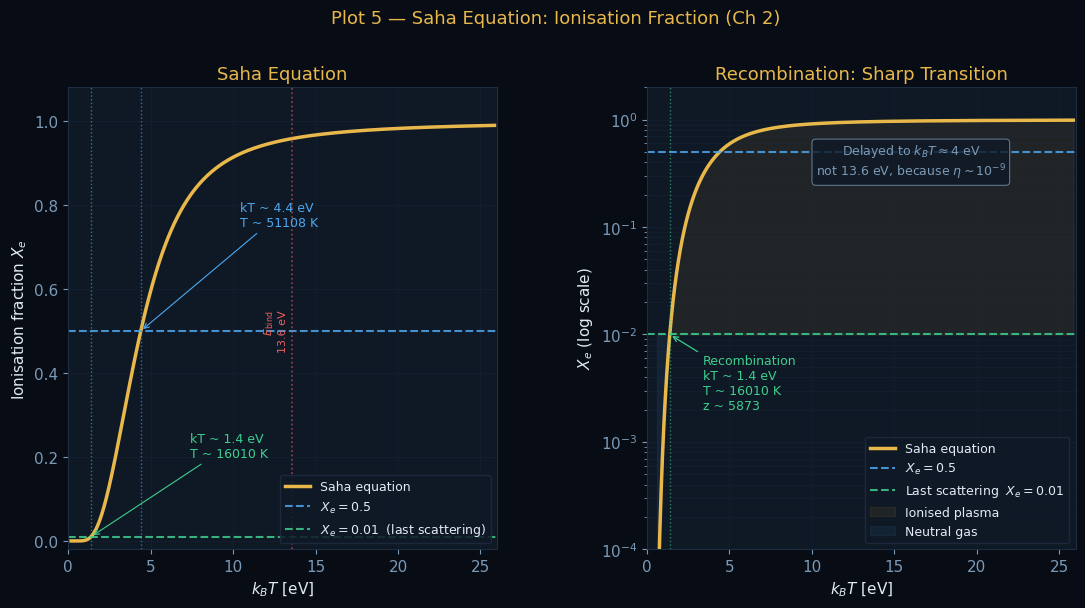

Plot 5 saved.
  Xe=0.5 at kT=4.40 eV,  T=51108 K
  Xe=0.01 at kT=1.38 eV,  T=16010 K,  z~5873


In [6]:
from scipy.special import zeta as riemann_zeta

kB_eV  = 8.617e-5
kB_si  = 1.3806e-23
me_c2  = 0.511e6 * 1.602e-19
E_bind = 13.6 * 1.602e-19
eta    = 6.0e-10
zeta3  = float(riemann_zeta(3))

def Xe_saha(T):
    """Ionisation fraction from Saha equation (log-space to avoid overflow)."""
    kT = kB_si * T
    log_rhs = (np.log(2*zeta3/np.pi**2) + np.log(eta)
               + 1.5*np.log(2*np.pi*me_c2/kT) + E_bind/kT)
    if log_rhs > 35:
        return 0.0
    rhs = np.exp(log_rhs)
    Xe  = (-1 + np.sqrt(1 + 4*rhs)) / (2*rhs)
    return float(np.clip(Xe, 0, 1))

# Temperature range 300,000 K → 2,000 K
T_arr  = np.linspace(300000, 2000, 4000)
Xe_arr = np.array([Xe_saha(T) for T in T_arr])
kT_eV  = kB_eV * T_arr

idx_half = np.argmin(np.abs(Xe_arr - 0.5))
idx_last = np.argmin(np.abs(Xe_arr - 0.01))
T_half   = T_arr[idx_half];  kT_half = kB_eV * T_half
T_last   = T_arr[idx_last];  kT_last = kB_eV * T_last

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))
fig.subplots_adjust(wspace=0.35)

# Left: linear scale
ax1.plot(kT_eV, Xe_arr, color=GOLD, lw=2.5, label='Saha equation')
ax1.axhline(0.5,  color=BLUE,  lw=1.5, ls='--', alpha=0.85, label=r'$X_e = 0.5$')
ax1.axhline(0.01, color=GREEN, lw=1.5, ls='--', alpha=0.85,
            label=r'$X_e = 0.01$  (last scattering)')
ax1.axvline(kT_half, color=BLUE,  lw=1.0, ls=':', alpha=0.6)
ax1.axvline(kT_last, color=GREEN, lw=1.0, ls=':', alpha=0.6)
ax1.axvline(13.6,    color=RED,   lw=1.2, ls=':', alpha=0.6)
ax1.text(13.6 - 0.3, 0.5, r'$E_\mathrm{bind}$' + '\n13.6 eV',
         color=RED, fontsize=8, rotation=90, va='center', ha='right')
ax1.annotate('kT ~ {:.1f} eV\nT ~ {:.0f} K'.format(kT_half, T_half),
             xy=(kT_half, 0.5), xytext=(kT_half + 6, 0.75),
             color=BLUE, fontsize=9,
             arrowprops=dict(arrowstyle='->', color=BLUE, lw=0.8))
ax1.annotate('kT ~ {:.1f} eV\nT ~ {:.0f} K'.format(kT_last, T_last),
             xy=(kT_last, 0.01), xytext=(kT_last + 6, 0.20),
             color=GREEN, fontsize=9,
             arrowprops=dict(arrowstyle='->', color=GREEN, lw=0.8))
ax1.set_xlabel(r'$k_BT$ [eV]')
ax1.set_ylabel(r'Ionisation fraction $X_e$')
ax1.set_title('Saha Equation')
ax1.set_xlim(0, 26); ax1.set_ylim(-0.02, 1.08)
ax1.grid(True, alpha=0.35)
ax1.legend(loc='lower right', fontsize=9, framealpha=0.85)

# Right: log scale
mask = Xe_arr > 1e-5
ax2.semilogy(kT_eV[mask], Xe_arr[mask], color=GOLD, lw=2.5, label='Saha equation')
ax2.axhline(0.5,  color=BLUE,  lw=1.5, ls='--', alpha=0.85, label=r'$X_e = 0.5$')
ax2.axhline(0.01, color=GREEN, lw=1.5, ls='--', alpha=0.85,
            label=r'Last scattering  $X_e = 0.01$')
ax2.axvline(kT_last, color=GREEN, lw=1.0, ls=':', alpha=0.6)
ax2.fill_between(kT_eV[mask], Xe_arr[mask], 0.01,
                 where=(Xe_arr[mask] > 0.01), color=GOLD, alpha=0.08,
                 label='Ionised plasma')
ax2.fill_between(kT_eV[mask], Xe_arr[mask], 0.01,
                 where=(Xe_arr[mask] < 0.01), color=BLUE, alpha=0.08,
                 label='Neutral gas')
ax2.annotate(
    'Recombination\nkT ~ {:.1f} eV\nT ~ {:.0f} K\nz ~ {:.0f}'.format(
        kT_last, T_last, T_last/2.726),
    xy=(kT_last, 0.01), xytext=(kT_last + 2, 2e-3),
    color=GREEN, fontsize=9,
    arrowprops=dict(arrowstyle='->', color=GREEN, lw=0.9))
ax2.text(16, 0.3,
         r'Delayed to $k_BT\approx4$ eV' + '\n'
         + r'not 13.6 eV, because $\eta\sim10^{-9}$',
         color=MUTED, fontsize=9, ha='center',
         bbox=dict(boxstyle='round,pad=0.3', fc='#0f1825',
                   ec=MUTED, alpha=0.8, lw=0.7))
ax2.set_xlabel(r'$k_BT$ [eV]')
ax2.set_ylabel(r'$X_e$ (log scale)')
ax2.set_title('Recombination: Sharp Transition')
ax2.set_xlim(0, 26); ax2.set_ylim(1e-4, 2)
ax2.grid(True, alpha=0.35, which='both')
ax2.legend(loc='lower right', fontsize=9, framealpha=0.85)

fig.suptitle('Plot 5 — Saha Equation: Ionisation Fraction (Ch 2)',
             fontsize=13, color=GOLD, y=1.01)
plt.savefig('cosmo_plot5_saha.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Plot 5 saved.')
print('  Xe=0.5 at kT={:.2f} eV,  T={:.0f} K'.format(kT_half, T_half))
print('  Xe=0.01 at kT={:.2f} eV,  T={:.0f} K,  z~{:.0f}'.format(
      kT_last, T_last, T_last/2.726))


---
## Plot 6 · Matter Power Spectrum $P(k)$ (Ch 3)

Starting from the Harrison-Zel'dovich initial spectrum $P(k)\propto k^{n_s}$,
the evolved spectrum is $P(k;t_0) = T^2(k)\cdot A k^{n_s}$ where the BBKS transfer function is:
$$T(q) = \frac{\ln(1+2.34q)}{2.34q}\left[1 + 3.89q + (16.1q)^2 + (5.46q)^3 + (6.71q)^4\right]^{-1/4}$$
with $q = k/(\Gamma\,h\,\text{Mpc}^{-1})$ and $\Gamma\approx\Omega_m h\approx0.21$.

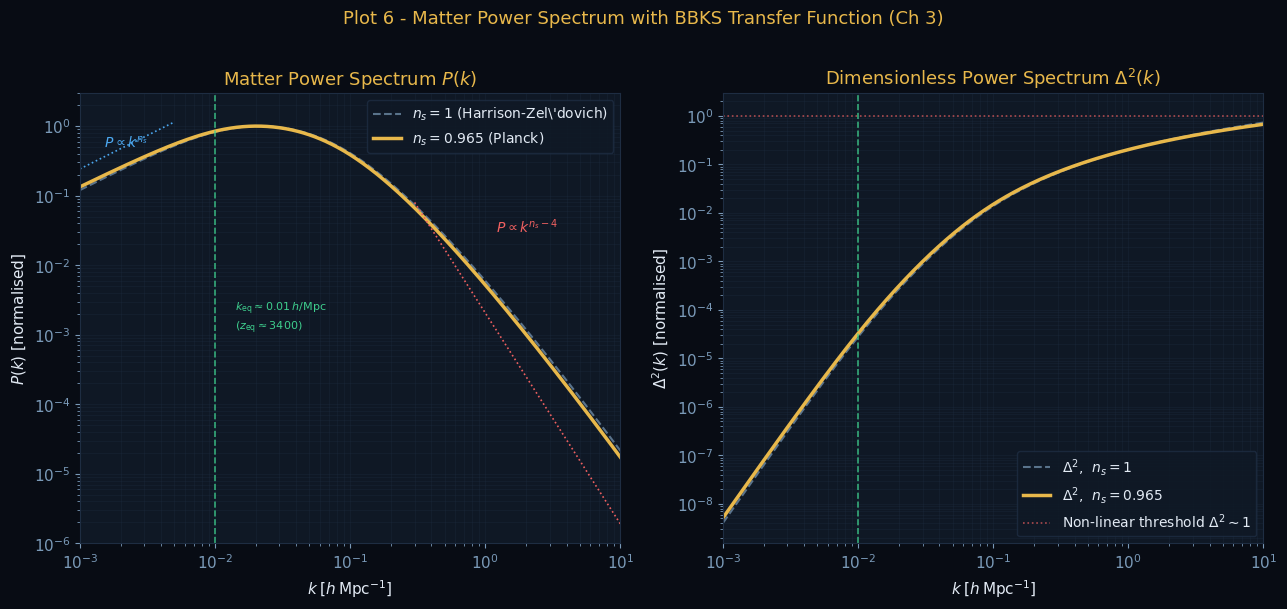

Plot 6 saved.


In [7]:
# BBKS transfer function
def T_BBKS(k, Gamma=0.21):
    q = k / Gamma
    return (np.log(1 + 2.34*q) / (2.34*q) *
            (1 + 3.89*q + (16.1*q)**2 + (5.46*q)**3 + (6.71*q)**4)**(-0.25))

k_arr   = np.logspace(-3, 1.5, 1000)
ns, ns_HZ, A_norm = 0.965, 1.000, 1.0
T_k      = T_BBKS(k_arr)
P_obs    = A_norm * k_arr**ns    * T_k**2
P_HZ_ev  = A_norm * k_arr**ns_HZ * T_k**2

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

# Left: P(k)
ax = axes[0]
ax.loglog(k_arr, P_HZ_ev/P_HZ_ev.max(), color=MUTED, lw=1.5, ls='--', alpha=0.7,
          label=r'$n_s = 1$ (Harrison-Zel\'dovich)')
ax.loglog(k_arr, P_obs/P_obs.max(), color=GOLD, lw=2.5,
          label=r'$n_s = 0.965$ (Planck)')
mask_L = k_arr < 0.005
mask_S = k_arr > 0.3
ax.loglog(k_arr[mask_L], 0.7*(k_arr[mask_L]/0.003)**ns,    color=BLUE, lw=1.2, ls=':')
ax.loglog(k_arr[mask_S], 0.08*(k_arr[mask_S]/0.3)**(ns-4), color=RED,  lw=1.2, ls=':')
ax.text(0.0015, 0.5, r'$P \propto k^{n_s}$',      color=BLUE, fontsize=10)
ax.text(1.2,   0.03, r'$P \propto k^{n_s - 4}$',  color=RED,  fontsize=10)
k_eq = 0.01
ax.axvline(k_eq, color=GREEN, lw=1.2, ls='--', alpha=0.8)
ax.text(k_eq*1.4, 1.2e-3,
        r'$k_\mathrm{eq}\approx0.01\,h/\mathrm{Mpc}$'+chr(10)+r'($z_\mathrm{eq}\approx3400$)',
        color=GREEN, fontsize=8)
ax.set_xlabel(r'$k\;[h\,\mathrm{Mpc}^{-1}]$')
ax.set_ylabel(r'$P(k)$ [normalised]')
ax.set_title(r'Matter Power Spectrum $P(k)$')
ax.set_xlim(1e-3, 10); ax.set_ylim(1e-6, 3)
ax.grid(True, alpha=0.35, which='both')
ax.legend(fontsize=10)

# Right: Delta^2(k)
ax = axes[1]
D2    = 4*np.pi * k_arr**3 * P_obs    / (2*np.pi)**3
D2_HZ = 4*np.pi * k_arr**3 * P_HZ_ev / (2*np.pi)**3
norm  = D2.max()
D2 /= norm; D2_HZ /= norm
ax.loglog(k_arr, D2_HZ, color=MUTED, lw=1.5, ls='--', alpha=0.7, label=r'$\Delta^2$,  $n_s=1$')
ax.loglog(k_arr, D2,    color=GOLD,  lw=2.5,           label=r'$\Delta^2$,  $n_s=0.965$')
ax.axhline(1.0, color=RED, lw=1.2, ls=':', alpha=0.7,
           label=r'Non-linear threshold $\Delta^2\sim1$')
ax.axvline(k_eq, color=GREEN, lw=1.2, ls='--', alpha=0.8)
ax.set_xlabel(r'$k\;[h\,\mathrm{Mpc}^{-1}]$')
ax.set_ylabel(r'$\Delta^2(k)$ [normalised]')
ax.set_title(r'Dimensionless Power Spectrum $\Delta^2(k)$')
ax.set_xlim(1e-3, 10)
ax.grid(True, alpha=0.35, which='both')
ax.legend(fontsize=10)

plt.suptitle('Plot 6 - Matter Power Spectrum with BBKS Transfer Function (Ch 3)',
             y=1.01, fontsize=13, color=GOLD)
plt.tight_layout()
plt.savefig('cosmo_plot6_power_spectrum.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Plot 6 saved.')


---
## Plot 7 · Spherical Collapse: True $\delta$ vs Linear Theory (Ch 3)

Parametric solution for an overdense sphere in an Einstein–de Sitter universe:
$$r(\tilde\phi) = A(1-\cos\tilde\phi), \quad t(\tilde\phi) = B(\tilde\phi-\sin\tilde\phi)$$
$$1+\delta = \frac{9}{2}\frac{(\tilde\phi-\sin\tilde\phi)^2}{(1-\cos\tilde\phi)^3}$$

Key milestones: turn-around ($\tilde\phi=\pi$, $\delta_\text{true}\approx4.55$, $\delta_\text{lin}\approx1.06$)
and collapse ($\tilde\phi=2\pi$, $\delta_\text{lin}\approx1.69$, $\delta_\text{vir}\approx177$).

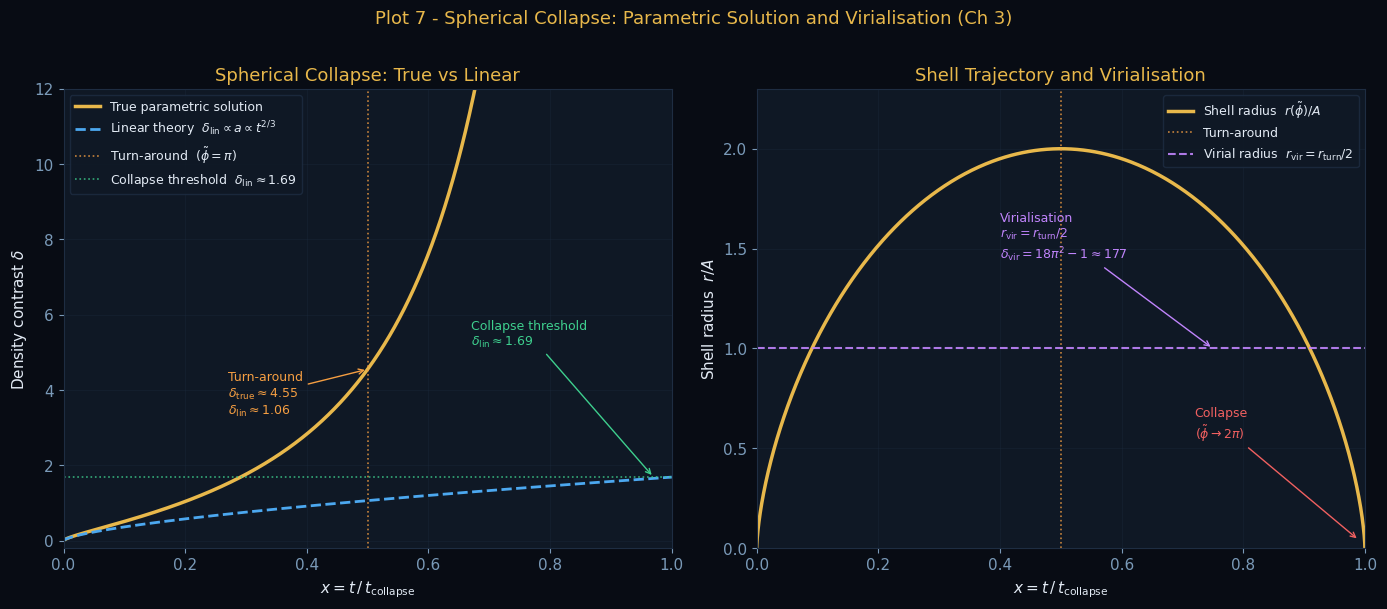

Plot 7 saved.
  Turn-around:  delta_true=4.552,  delta_lin=1.0623
  Collapse threshold: delta_lin=1.6863
  Virialised overdensity: delta_vir=176.7


In [8]:
phi = np.linspace(1e-6, 2*np.pi - 0.005, 5000)
delta_true = 9/2 * (phi - np.sin(phi))**2 / (1 - np.cos(phi))**3 - 1
x    = (phi - np.sin(phi)) / (2*np.pi)
x_ta = 0.5
delta_lin = 1.0623 * (x / x_ta)**(2/3)
delta_true_ta = 9*np.pi**2/16 - 1
delta_lin_ta  = 1.0623
delta_lin_col = 1.0623 / x_ta**(2/3)
delta_vir     = 18*np.pi**2 - 1

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: delta(x)
ax = axes[0]
mask = delta_true < 50
ax.plot(x[mask], delta_true[mask], color=GOLD, lw=2.5, label='True parametric solution')
ax.plot(x, delta_lin, color=BLUE, lw=2.0, ls='--',
        label=r'Linear theory  $\delta_\mathrm{lin} \propto a \propto t^{2/3}$')
ax.axvline(x_ta, color=ORANGE, lw=1.2, ls=':', alpha=0.8,
           label=r'Turn-around  ($\tilde\phi = \pi$)')
ax.axhline(delta_lin_col, color=GREEN, lw=1.2, ls=':', alpha=0.8,
           label=r'Collapse threshold  $\delta_\mathrm{lin} \approx 1.69$')
ax.annotate(
    'Turn-around\n'
    r'$\delta_\mathrm{true} \approx 4.55$' + '\n'
    r'$\delta_\mathrm{lin}  \approx 1.06$',
    xy=(x_ta, delta_true_ta), xytext=(x_ta - 0.23, delta_true_ta - 1.2),
    color=ORANGE, fontsize=9, arrowprops=dict(arrowstyle='->', color=ORANGE, lw=1))
ax.annotate(
    r'Collapse threshold' + '\n' + r'$\delta_\mathrm{lin} \approx 1.69$',
    xy=(0.97, delta_lin_col), xytext=(0.67, delta_lin_col + 3.5),
    color=GREEN, fontsize=9, arrowprops=dict(arrowstyle='->', color=GREEN, lw=1))
ax.set_xlabel(r'$x = t \,/\, t_\mathrm{collapse}$')
ax.set_ylabel(r'Density contrast $\delta$')
ax.set_title('Spherical Collapse: True vs Linear')
ax.set_xlim(0, 1.0); ax.set_ylim(-0.2, 12)
ax.grid(True, alpha=0.35)
ax.legend(fontsize=9, loc='upper left')

# Right: shell radius
ax = axes[1]
phi2  = np.linspace(1e-4, 2*np.pi, 1000)
r_phi = 1 - np.cos(phi2)
t_phi = (phi2 - np.sin(phi2)) / (2*np.pi)
ax.plot(t_phi, r_phi, color=GOLD, lw=2.5, label=r'Shell radius  $r(\tilde\phi)/A$')
ax.axvline(0.5, color=ORANGE, lw=1.2, ls=':', alpha=0.8, label='Turn-around')
ax.axhline(1.0, color=PURPLE, lw=1.5, ls='--', alpha=0.9,
           label=r'Virial radius  $r_\mathrm{vir} = r_\mathrm{turn}/2$')
ax.annotate(
    'Virialisation\n'
    r'$r_\mathrm{vir} = r_\mathrm{turn}/2$' + '\n'
    r'$\delta_\mathrm{vir} = 18\pi^2 - 1 \approx 177$',
    xy=(0.75, 1.0), xytext=(0.40, 1.45),
    color=PURPLE, fontsize=9, arrowprops=dict(arrowstyle='->', color=PURPLE, lw=1))
ax.annotate('Collapse\n' + r'($\tilde\phi \to 2\pi$)',
    xy=(0.99, 0.04), xytext=(0.72, 0.55),
    color=RED, fontsize=9, arrowprops=dict(arrowstyle='->', color=RED, lw=1))
ax.set_xlabel(r'$x = t \,/\, t_\mathrm{collapse}$')
ax.set_ylabel(r'Shell radius  $r/A$')
ax.set_title('Shell Trajectory and Virialisation')
ax.set_xlim(0, 1.0); ax.set_ylim(0, 2.3)
ax.grid(True, alpha=0.35)
ax.legend(fontsize=9)

plt.suptitle('Plot 7 - Spherical Collapse: Parametric Solution and Virialisation (Ch 3)',
             y=1.01, fontsize=13, color=GOLD)
plt.tight_layout()
plt.savefig('cosmo_plot7_spherical_collapse.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Plot 7 saved.')
print('  Turn-around:  delta_true={:.3f},  delta_lin={:.4f}'.format(delta_true_ta, delta_lin_ta))
print('  Collapse threshold: delta_lin={:.4f}'.format(delta_lin_col))
print('  Virialised overdensity: delta_vir={:.1f}'.format(delta_vir))


---
## Summary

| Plot | File | Key result |
|------|------|------------|
| 1 | `cosmo_plot1_scale_factor.png` | $a(t)$: matter $t^{2/3}$, radiation $t^{1/2}$, de Sitter $e^{Ht}$, real universe |
| 2 | `cosmo_plot2_energy_density.png` | $\rho_r\propto a^{-4}$, $\rho_m\propto a^{-3}$, $\rho_\Lambda=$const; equality epochs |
| 3 | `cosmo_plot3_inflation_horizon.png` | Co-moving horizon shrinks during inflation; mode exit and re-entry |
| 4 | `cosmo_plot4_thermal_history.png` | $T(t)$: BBN at 1 s, recombination at 350,000 yr, CMB today at 2.73 K |
| 5 | `cosmo_plot5_saha.png` | $X_e(T)$: recombination delayed to $k_BT\approx0.3$ eV because $\eta\sim10^{-9}$ |
| 6 | `cosmo_plot6_power_spectrum.png` | $P(k)\propto k$ (large scales) → $k^{-3}$ (small scales); turnover at $k_\text{eq}$ |
| 7 | `cosmo_plot7_spherical_collapse.png` | $\delta_c=1.69$, $\delta_\text{vir}=18\pi^2-1\approx177$, $r_\text{vir}=r_\text{turn}/2$ |